# Language model

Khi gõ “em học”, bàn phím có thể gợi ý “toán”, “tin”, hoặc một từ không hợp ngữ cảnh. Mô hình đang làm việc khác với bộ phân loại nhận xét: nó không chọn một nhãn cho cả câu mà dự đoán **token tiếp theo từ tiền tố đang có**. Nếu lặp thao tác ấy, ta sinh được một chuỗi. Bài này dùng bigram để tính từng xác suất, rồi nối sang causal transformer và các chiến lược decoding. Ta cũng xem vì sao câu trôi chảy hoặc perplexity thấp chưa chứng minh câu đúng hay do ai viết.

> **Mục tiêu sau bài này**
>
> - Viết xác suất của chuỗi thành tích xác suất có điều kiện, từ n-gram đến causal transformer.
> - Dựng label dịch một vị trí, tính cross-entropy và perplexity trên cùng một giao thức tokenization.
> - So sánh greedy, sampling, temperature, top-k, top-p và beam search.
> - Đọc giới hạn của điểm language model khi phát hiện văn bản bị máy sửa.

## Mỗi bước chọn từ một phân phối

Với chuỗi token $t_1,\ldots,t_L$, quy tắc nhân xác suất cho

$$p(t_1,\ldots,t_L)=\prod_{i=1}^{L}p(t_i\mid t_1,\ldots,t_{i-1}).$$

Ta thêm BOS (bắt đầu) và EOS (kết thúc) để model biết khi nào bắt đầu hoặc dừng. BOS thường là điều kiện đầu vào, EOS là một token cần dự đoán. Nếu không có EOS hoặc giới hạn số token, vòng sinh có thể không dừng. Token ở đây theo tokenizer đã chọn, có thể là âm tiết, subword hoặc byte; “next word” chỉ là cách nói gần gũi, tên nhiệm vụ chính xác là next-token prediction. Đoán token tiếp theo, nối vào, rồi đoán tiếp là cách mọi model kiểu GPT sinh văn bản; gợi ý từ tiếp theo trên bàn phím điện thoại là phiên bản nhỏ của cùng ý.

Bigram chỉ nhìn một token trước: $p(t_i\mid t_{i-1})$; trigram nhìn hai token trước. N-gram dùng cửa sổ cố định nên dễ đếm và kiểm, nhưng không theo dõi được ngữ cảnh dài. Bảng của nó còn phình rất nhanh: với vocabulary $V$, n-gram có $|V|^{n-1}$ ngữ cảnh, mỗi ngữ cảnh một phân phối trên $|V|$ token. Với $|V|=10\,000$, trigram đã có $10^8$ ngữ cảnh, mỗi ngữ cảnh cần $10^4$ xác suất; một corpus vài triệu token chỉ gặp được một phần nhỏ trong số đó, nên phần lớn ô của bảng không bao giờ được đếm. Causal transformer dùng self-attention trên tiền tố: tại vị trí $i$, nó không được đọc token tương lai dùng làm nhãn. BERT ở bài 6.3 nhìn hai chiều cho MLM; nó không phải causal language model chỉ cần gọi vòng sinh là thành GPT.



**Hỏi nhanh.** Một model không dùng EOS, nên xác suất của một câu là tích xác suất của các token chữ. So câu hoàn chỉnh “em học” với câu “em học toán”, điều gì luôn đúng?

- A. “em học toán” cao hơn, vì có thêm một từ hợp ngữ cảnh
- B. “em học” không thấp hơn, vì nó là tiền tố của câu kia
- C. Hai câu bằng nhau, vì có chung tiền tố “em học”
- D. Không so được khi chưa biết $p(\text{toán}\mid\text{em học})$

<details><summary>Đáp án</summary>

B. “em học” không thấp hơn, vì nó là tiền tố của câu kia

Không có EOS thì $p(\text{em học toán}) = p(\text{em học})\cdot p(\text{toán}\mid\text{em học})$. Thừa số thêm vào không vượt 1, nên tích không thể tăng. Điều này đúng với mọi giá trị, không cần biết $p(\text{toán}\mid\text{em học})$. Hai câu chỉ bằng nhau khi thừa số ấy đúng bằng 1. Hệ quả là model ưu ái mọi câu bị cắt ngắn, và không có cách nào nói “câu dừng ở đây”. Có EOS thì câu hoàn chỉnh “em học” cần thêm thừa số $p(\mathrm{EOS}\mid\text{em học})$, nên nó có thể kém “em học toán” khi “học” hiếm khi đứng cuối câu.

</details>

## Học một bigram trên corpus tự soạn

Ta dùng năm câu train. Từ vựng đích gồm bảy token chữ, EOS và UNK; BOS không nằm trong danh sách token được sinh. Vocabulary chỉ được rút từ train. Với token lạ ở evaluation, ta chuyển sang UNK, không âm thầm thêm cột mới.

In [ ]:
from collections import Counter, defaultdict
import numpy as np

train_sentences = ["em học toán", "em học tin", "em đọc sách", "bạn học toán", "bạn đọc sách"]
BOS, EOS, UNK = "<bos>", "<eos>", "<unk>"
target_vocab = sorted({token for text in train_sentences for token in text.split()} | {EOS, UNK})
bigram_counts = defaultdict(Counter)
for text in train_sentences:
    tokens = [BOS] + text.split() + [EOS]
    for previous, following in zip(tokens, tokens[1:]):
        bigram_counts[previous][following] += 1

print("vocabulary size:", len(target_vocab))
print("sau 'em':", dict(bigram_counts["em"]))

vocabulary size: 9
sau 'em': {'học': 2, 'đọc': 1}


Sau “em”, “học” xuất hiện hai lần và “đọc” một lần. Ước lượng không làm trơn cho $p(\text{học}\mid\text{em})=2/3$. Tương tự, “con” xuất hiện 200 lần và “con mèo” 30 lần cho $p(\text{mèo}\mid\text{con}) = 0.15$. Nhưng một cặp chưa thấy có xác suất 0, và chỉ một thừa số 0 cũng khiến cả tích chuỗi bằng 0. Ta dùng add-$\alpha$ smoothing, ở đây $\alpha=1$:



$$p(v\mid u)=\frac{c(u,v)+\alpha}{\sum_{w\in V}c(u,w)+\alpha|V|}.$$

Mỗi token trong vocabulary được cộng cùng một số đếm giả $\alpha$, rồi chia cho tổng mới nên phân phối vẫn cộng thành 1.



In [ ]:
alpha = 1.0

def next_distribution(previous):
    counts = bigram_counts.get(previous, Counter())
    denominator = sum(counts.values()) + alpha * len(target_vocab)
    return np.array([(counts[token] + alpha) / denominator for token in target_vocab])

em_distribution = next_distribution("em")
print("p(học|em):", round(em_distribution[target_vocab.index("học")], 3))
print("tổng xác suất:", round(em_distribution.sum(), 6))

p(học|em): 0.25
tổng xác suất: 1.0


Đối chiếu bằng tay: tử số là $2+1=3$, mẫu số $3+9=12$, nên xác suất giảm từ $2/3$ xuống 0.25. Add-$\alpha$ cho mỗi ngữ cảnh cùng một tổng số đếm giả $\alpha|V|$. Ngữ cảnh càng ít gặp và vocabulary càng lớn thì phần giả này càng lấn át số đếm thật, và phần lớn xác suất bị chia cho những token chưa từng đi sau ngữ cảnh đó. Vì vậy với corpus thật, nếu dùng add-$\alpha$ thì thường chọn $\alpha<1$ (chẳng hạn 0.5, 0.05 hay 0.01); dù vậy add-$\alpha$ vẫn kém cho language model, nên thực tế người ta dùng interpolation với n-gram ngắn hơn hoặc Kneser–Ney (xem Đọc thêm). $\alpha$ là hyperparameter phải chọn trên validation, không nhìn test rồi chọn số làm test đẹp nhất.

**Hỏi nhanh.** Bỏ smoothing, tức $\alpha = 0$. Một câu validation có 20 cặp token. 19 cặp đã gặp trong train với xác suất cao, còn một cặp chưa gặp. NLL trung bình của câu bằng bao nhiêu?

- A. Gần NLL của 19 cặp kia, vì một cặp chỉ chiếm 1/20
- B. Bằng NLL của 19 cặp kia, vì cặp chưa gặp bị bỏ qua
- C. Vô cùng, vì $-\log 0$ không hữu hạn
- D. Lớn nhưng hữu hạn, vì xác suất ấy chỉ rất nhỏ

<details><summary>Đáp án</summary>

C. Vô cùng, vì $-\log 0$ không hữu hạn

Cặp chưa gặp có xác suất đúng bằng 0, chứ không phải rất nhỏ. Số hạng $-\log 0 = +\infty$, nên trung bình cũng vô cùng. Chỉ một cặp như vậy là đủ làm PPL của cả tập validation thành vô cùng. Trong NumPy, `np.log(0)` cho `-inf` kèm một cảnh báo. Lấy trung bình không pha loãng được một số hạng vô cùng. Bỏ cặp ấy khỏi tổng là đổi phép đo, vì chỉ vị trí đệm mới được bỏ. Smoothing cho mọi cặp một xác suất dương, nên NLL luôn hữu hạn.

</details>

**Hỏi nhanh.** Giữ đúng số đếm sau “em”, gồm “học” 2 lần và “đọc” 1 lần, nhưng vocabulary đích có 10 000 token. Với add-1, $p(\text{học}\mid\text{em})$ xấp xỉ bao nhiêu?

- A. 0.0003
- B. 0.25, như với vocabulary 9 token
- C. 0.6, vì chỉ token đã gặp mới được cộng 1
- D. 0.667, vì add-1 giữ nguyên tỉ lệ 2:1

<details><summary>Đáp án</summary>

A. 0.0003

$(2 + 1)/(3 + 10\,000) \approx 0.0003$. Hai token đã gặp chỉ còn giữ $(3 + 2)/10\,003 \approx 0.05\%$ khối xác suất. 99.95% còn lại chia đều cho 9998 token chưa từng đi sau “em”. 0.25 là con số của vocabulary 9 token. Số đếm giả được cộng cho mọi token trong vocabulary, không chỉ token đã gặp, nên 0.6 sai. 0.667 là ước lượng khi không làm trơn. Đây là lý do add-1 quá mạnh khi vocabulary lớn.

</details>

## Label dịch một vị trí, loss và perplexity

Trong huấn luyện next-token prediction, input và label lệch một vị trí. Với chuỗi `[BOS, em, học, toán, EOS]`, input là `[BOS, em, học, toán]`, label là `[em, học, toán, EOS]`. Token PAD trong label được bỏ khỏi loss. Khi dùng causal mask, các vị trí input được xử lý đồng thời trong train mà vẫn không đọc tương lai. Khi suy luận, ta chưa biết label thật nên phải dùng token vừa sinh làm input cho bước kế tiếp.

Average negative log-likelihood trên $N$ token đích hợp lệ là

$$\mathcal{H}=-\frac{1}{N}\sum_{i=1}^{N}\log p(t_i\mid\text{tiền tố}),\qquad \operatorname{PPL}=e^{\mathcal{H}}.$$

Ta dùng log tự nhiên nên perplexity là `exp(loss)`. Nếu dùng log cơ số 2 thì là $2^{\mathcal{H}}$. Perplexity có thể hiểu như mức bất định hiệu dụng: model cho xác suất đúng bằng $1/4$ ở mọi bước có PPL bằng 4. Nó không phải số token sai hay số từ trong câu. Cross-entropy 3 bit mỗi token cho PPL $2^3 = 8$; model chia đều xác suất cho 50 000 token có PPL đúng 50 000. Ngay cả model hoàn hảo cũng không xuống dưới entropy của chính phân phối dữ liệu, nên PPL có một sàn lớn hơn 1.

In [ ]:
def sentence_nll(text):
    words = [word if word in target_vocab else UNK for word in text.split()]
    tokens = [BOS] + words + [EOS]
    log_probabilities = []
    for previous, following in zip(tokens, tokens[1:]):
        probability = next_distribution(previous)[target_vocab.index(following)]
        log_probabilities.append(np.log(probability))
    return -np.mean(log_probabilities), len(log_probabilities)

for text in ["em học toán", "em sách học", "robot học toán"]:
    nll, count = sentence_nll(text)
    print(text, "N=", count, "NLL=", round(nll, 3), "PPL=", round(np.exp(nll), 3))
print("PPL xác suất 1/4:", round(np.exp(-np.log(0.25)), 3))

em học toán N= 4 NLL= 1.331 PPL= 3.785
em sách học N= 4 NLL= 2.155 PPL= 8.629
robot học toán N= 4 NLL= 1.88 PPL= 6.557
PPL xác suất 1/4: 4.0


Số đếm $N$ có cả EOS. So “em học toán” với “em sách học”: model đếm thích trật tự nó đã thấy hơn. Query có “robot” bị chuyển UNK, nên kết quả cũng phụ thuộc quy tắc xử lý từ lạ. Các câu trên là probe do ta đặt; câu đầu còn có trong train. Muốn báo chất lượng language model, cần corpus evaluation độc lập theo tài liệu hoặc thời gian.



Causal neural language model tính cùng đại lượng theo cách khác: nó nhận cả chuỗi input một lần, trả một hàng logits cho mỗi vị trí, rồi so hàng thứ $i$ với label thứ $i$ bằng cross-entropy. Bigram cũng viết được như vậy, vì hàng ở vị trí $i$ chỉ phụ thuộc token $i$. Ta dùng log-xác suất làm logits: các xác suất đã cộng thành 1 nên softmax trả lại đúng phân phối cũ.

In [ ]:
import torch
import torch.nn.functional as F

def bigram_logits(tokens):
    # Hàng i chỉ đọc tokens[i]: một causal language model có ngữ cảnh dài 1.
    rows = [np.log(next_distribution(token)) for token in tokens]
    return torch.tensor(np.array(rows), dtype=torch.float32)

sequence = [BOS, "em", "học", "toán", EOS]
inputs, labels = sequence[:-1], sequence[1:]
logits = bigram_logits(inputs)
label_ids = torch.tensor([target_vocab.index(token) for token in labels])
print("input:", inputs)
print("label:", labels)
print("logits shape:", tuple(logits.shape))
print("cross-entropy:", round(F.cross_entropy(logits, label_ids).item(), 3))

# Thêm hai vị trí đệm; label -100 bị cross_entropy bỏ qua theo mặc định.
padded_logits = bigram_logits(inputs + [EOS, EOS])
padded_labels = torch.cat([label_ids, torch.tensor([-100, -100])])
print("thêm 2 vị trí đệm:", round(F.cross_entropy(padded_logits, padded_labels).item(), 3))

input: ['<bos>', 'em', 'học', 'toán']
label: ['em', 'học', 'toán', '<eos>']
logits shape: (4, 9)
cross-entropy: 1.331
thêm 2 vị trí đệm: 1.331


Cross-entropy 1.331 khớp NLL của “em học toán” ở trên: loss huấn luyện của language model chính là NLL trung bình trên các token đích. Hai vị trí đệm mang label `-100` nên loss giữ nguyên, dù hàng logits ở đó chứa gì. Với batch thật, input có shape `(B, L)`, logits có shape `(B, L, |V|)`, và label là chính chuỗi token dịch trái một vị trí, nên mỗi chuỗi $L$ token cho $L-1$ cặp (vị trí, token kế). Quên dịch label, tức dùng chính `input_ids` làm nhãn ở cùng vị trí, thì model chỉ học chép lại token đang đọc: loss xuống rất thấp mà không học được gì về token tiếp theo.

**Hỏi nhanh.** Batch `ids` có shape `(8, 128)`. Model trả về `logits` shape `(8, 128, V)`, trong đó logits ở vị trí $i$ dự đoán token $i + 1$. Đưa cặp nào vào cross-entropy mới đúng?

- A. `logits[:, :-1]` với `ids[:, 1:]`
- B. `logits[:, 1:]` với `ids[:, :-1]`
- C. `logits[:, :-1]` với `ids[:, :-1]`
- D. `logits` với `ids`, không cắt gì

<details><summary>Đáp án</summary>

A. `logits[:, :-1]` với `ids[:, 1:]`

Vị trí cuối không có token kế, nên bỏ hàng logits cuối. Label của vị trí $i$ là `ids[:, i+1]`, nên bỏ token đầu của label. Mỗi chuỗi còn 127 cặp. Cắt ngược chiều thì bắt vị trí $i + 1$ đoán token $i$, một token nó đã đọc được. Không dịch, như hai phương án sau, thì bắt mỗi vị trí đoán chính token nó đang đọc. Token ấy nằm ngay trong input, nên loss xuống gần 0 mà model không học được gì về dự đoán. Cắt đúng xong thì flatten thành `(8·127, V)` và `(8·127,)`, rồi gọi `F.cross_entropy`.

</details>

Không so PPL của hai tokenizer khác nhau như cùng một thước đo: chuỗi bị chia khác làm $N$ và phân phối đích đổi. Phải nói rõ tokenizer, vocabulary, cách tính BOS/EOS, truncation và đơn vị trung bình. Loss phải cộng theo tổng số token hợp lệ; trung bình loss của các batch dài ngắn bằng trọng số ngang nhau có thể làm lệch phép đo.

**Hỏi nhanh.** Hai câu dùng để đánh giá có 2 và 8 token hợp lệ. Muốn NLL trung bình theo token thì gộp thế nào?

- A. Lấy trung bình hai loss câu, mỗi câu trọng số 1/2
- B. Bỏ câu ngắn, vì 2 token quá ít để đo
- C. Cộng NLL của cả 10 token rồi chia cho 2 câu
- D. Cộng NLL của cả 10 token rồi chia cho 10

<details><summary>Đáp án</summary>

D. Cộng NLL của cả 10 token rồi chia cho 10

Mỗi token đích có trọng số ngang nhau, nên lấy tổng NLL chia cho số token hợp lệ. Trung bình hai loss câu thì mỗi token của câu ngắn có trọng số gấp bốn token của câu dài. Đó là metric theo câu, khác với metric theo token. Chia tổng cho số câu thì ra NLL trung bình mỗi câu, một đại lượng phụ thuộc độ dài câu. Bỏ bớt dữ liệu khỏi tập đánh giá là đổi chính phép đo.

</details>

## Từ logits đến token được chọn

Causal neural language model trả logits $z_v$ cho mọi token trong vocabulary. Với temperature $T>0$, xác suất dùng khi sampling là

$$p_T(v)=\frac{e^{z_v/T}}{\sum_w e^{z_w/T}}.$$

$T$ nhỏ làm phân phối nhọn, $T$ lớn làm phẳng. Greedy luôn lấy token có logits lớn nhất; chia mọi logits cho cùng một $T>0$ không đổi thứ tự, nên temperature không ảnh hưởng tới greedy. Không tính công thức với $T=0$; “temperature 0” trong một số API là quy ước chuyển sang greedy, không phải phép chia toán học hợp lệ.



In [ ]:
def softmax_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("Temperature phải dương trong công thức sampling")
    scaled = logits / temperature
    weights = np.exp(scaled - scaled.max())
    return weights / weights.sum()

example_logits = np.array([2.0, 1.0, 0.0])
for temperature in [0.5, 1.0, 2.0]:
    probability = softmax_temperature(example_logits, temperature)
    print("T=", temperature, "p=", probability.round(3))

T= 0.5 p= [0.867 0.117 0.016]
T= 1.0 p= [0.665 0.245 0.09 ]
T= 2.0 p= [0.506 0.307 0.186]


Token đầu vẫn có xác suất lớn nhất ở cả ba hàng; chỉ độ chênh thay đổi. Khi $T\to0^+$, phân phối dồn về argmax nên sampling tiến tới greedy; khi $T\to\infty$, nó tiến tới phân phối đều trên cả vocabulary. Sampling lấy ngẫu nhiên theo phân phối, không nhất thiết chọn token đầu. Cố định seed giúp tái tạo cùng thí nghiệm trong cùng môi trường, nhưng không biến sampling thành kiểm chứng kiến thức.

Top-k giữ đúng $k$ token có điểm cao nhất rồi chuẩn hóa lại. Top-p giữ một tiền tố nhỏ nhất của danh sách đã sắp mà tổng xác suất đạt ít nhất $p$, rồi chuẩn hóa lại. Số token top-p giữ thay đổi theo độ nhọn; phải giữ cả token vượt qua ngưỡng, không chỉ những token có cumulative probability nhỏ hơn $p$.

In [ ]:
def top_p_distribution(probability, threshold):
    if not 0 < threshold <= 1:
        raise ValueError("top-p nằm trong (0, 1]")
    order = np.argsort(-probability, kind="stable")
    sorted_probability = probability[order]
    # Giữ token khi tổng trước nó còn dưới ngưỡng, gồm cả token vượt ngưỡng.
    keep = np.cumsum(sorted_probability) - sorted_probability < threshold
    result = np.zeros_like(probability)
    result[order[keep]] = sorted_probability[keep]
    return result / result.sum()

base_probability = softmax_temperature(example_logits, 1.0)
filtered = top_p_distribution(base_probability, 0.8)
print("base:", base_probability.round(3))
print("top-p=0.8:", filtered.round(3))
print("số token giữ:", np.count_nonzero(filtered))

base: [0.665 0.245 0.09 ]
top-p=0.8: [0.731 0.269 0.   ]
số token giữ: 2


Top-p 0.8 giữ hai token: token đầu (0.665) chưa đạt 0.8, còn hai token đầu (0.91) đã đạt. Top-k giữ một số token cố định dù phân phối nhọn hay phẳng; top-p tự co lại khi model chắc chắn và nới ra khi model phân vân. Các thư viện như Hugging Face áp temperature vào logits trước, rồi mới lọc top-k và top-p trên phân phối đã đổi. Ví dụ “và” 0.5, “nhưng” 0.3, “nên” 0.1, “thì” 0.1 với top-p 0.75: token đầu chưa đủ, hai token đầu đạt 0.8, nên chỉ chọn giữa “và” và “nhưng”. Cũng vì sampling mà hỏi chatbot cùng một câu hai lần có thể nhận hai câu trả lời khác nhau. Việc cần chính xác như dịch hợp đồng hợp với greedy hay beam search; viết truyện cần đa dạng thì hợp với sampling có temperature vừa phải.

**Hỏi nhanh.** Vẫn logits (2, 1, 0), nhưng hạ temperature từ 1 xuống 0.5 rồi mới lọc. Top-p 0.8 và top-k 2 lần lượt giữ bao nhiêu token?

- A. Top-p giữ 2, top-k giữ 2
- B. Top-p giữ 1, top-k giữ 2
- C. Top-p giữ 1, top-k giữ 1
- D. Top-p giữ 2, top-k giữ 1

<details><summary>Đáp án</summary>

B. Top-p giữ 1, top-k giữ 2

Ở $T = 0.5$, token đầu có xác suất 0.867, đã vượt 0.8, nên top-p chỉ giữ nó. Ở $T = 1$ thì top-p giữ hai token. Top-k giữ hai token có logits lớn nhất, và temperature dương không đổi thứ tự, nên tập top-k không đổi theo $T$. Trả lời top-p vẫn giữ 2 là đọc nhầm phân phối ở $T = 1$. Trả lời top-k còn 1 là tưởng temperature đổi số token mà top-k giữ.

</details>

**Hỏi nhanh.** Hai bước sinh có phân phối đã sắp là (0.97, 0.01, 0.01, 0.01) và (0.3, 0.3, 0.2, 0.2). Top-p 0.9 giữ bao nhiêu token ở mỗi bước?

- A. 2 và 2, như top-k 2
- B. 4 và 1
- C. 1 và 4
- D. 1 và 3

<details><summary>Đáp án</summary>

C. 1 và 4

Ở bước nhọn, 0.97 đạt 0.9 ngay ở token đầu, nên giữ 1. Ở bước phẳng, tổng dồn 0.3, 0.6, 0.8 vẫn dưới 0.9, phải thêm token thứ tư để tổng thành 1.0, nên giữ 4. “1 và 3” là quên token làm tổng vượt ngưỡng. “4 và 1” đảo vai hai phân phối. “2 và 2” là top-k 2, con số không đổi theo phân phối. Top-p giữ ít token khi model chắc chắn, và giữ nhiều token khi model phân vân.

</details>



## Sinh từng bước và vì sao greedy không tối ưu cả chuỗi

Ta cho bigram sinh đến EOS hoặc tối đa 6 token. Greedy dùng `argmax`, sampling dùng RNG seed 0. Khi hòa điểm, thứ tự `target_vocab` quyết định greedy, nên quy tắc đó phải được biết.

In [ ]:
def generate_bigram(sample=False, seed=0, max_tokens=6):
    rng = np.random.default_rng(seed)
    previous = BOS
    generated = []
    for _ in range(max_tokens):
        probability = next_distribution(previous)
        if sample:
            index = rng.choice(len(target_vocab), p=probability)
        else:
            index = int(probability.argmax())
        token = target_vocab[index]
        if token == EOS:
            break
        generated.append(token)
        previous = token
    return " ".join(generated)

print("greedy:", generate_bigram())
print("sampling seed 0:", generate_bigram(sample=True))

greedy: em học toán
sampling seed 0: em em


Greedy đi đúng đường được đếm nhiều nhất: “em” (3 lần sau BOS), “học”, “toán”, rồi EOS. Sampling với seed 0 ra “em em”, một cặp chưa từng xuất hiện: smoothing cho nó xác suất $1/12$, đủ để thỉnh thoảng được rút. Giới hạn số token giữ cho vòng sinh dừng, nhưng không sửa chất lượng. Chọn seed cho ra một câu hay rồi báo như thể model luôn sinh như vậy là chọn mẫu đẹp, giống chọn seed tốt nhất trên test. Câu trả lời bị cắt ngang giữa câu thường do chạm giới hạn số token sinh trước khi gặp EOS. Greedy còn hay rơi vào vòng lặp: khi cụm vừa sinh làm chính nó có xác suất cao nhất ở bước sau, argmax cứ chọn lại mãi; sampling hoặc phạt lặp (repetition penalty) phá vòng ấy.

**Hỏi nhanh.** Bỏ giới hạn số token. Sinh greedy trên một bigram có 9 token đích, trong đó có EOS. Đã sinh 9 token mà chưa gặp EOS. Điều gì là chắc chắn?

- A. Sắp gặp EOS, vì smoothing cho EOS xác suất dương
- B. Chưa kết luận được, phải chạy tiếp mới biết
- C. Chỉ lặp mãi nếu có hai token liền nhau giống nhau
- D. Sẽ không bao giờ gặp EOS, vì chuỗi đã vào một chu trình

<details><summary>Đáp án</summary>

D. Sẽ không bao giờ gặp EOS, vì chuỗi đã vào một chu trình

Với greedy trên bigram, token kế chỉ phụ thuộc token trước, nên dãy token là một hàm lặp trên một tập hữu hạn. Chỉ có 8 token khác EOS, nên trong 9 token đã sinh phải có một token lặp lại, theo nguyên lý chuồng bồ câu. Từ đó dãy đi lại đúng đoạn cũ mãi mãi. Xác suất dương của EOS chỉ có tác dụng khi sampling. Greedy không chọn EOS nếu nó không phải argmax. Chu trình có thể dài hơn 1, như “học toán học toán”. Model có ngữ cảnh dài thì không còn là hàm của một token, nhưng greedy lặp lại một cụm từ vẫn là lỗi quen thuộc, và giới hạn số token là chốt chặn cuối.

</details>

Greedy tối ưu mỗi bước, không bảo đảm tối ưu cả chuỗi. Ví dụ bước đầu $p(A)=0.6$, $p(B)=0.4$. Tiếp theo $p(\mathrm{EOS}\mid A)=0.5$, còn $p(\mathrm{EOS}\mid B)=0.95$. Greedy chọn A, chuỗi `A EOS` có xác suất $0.6\cdot0.5=0.30$, còn `B EOS` có $0.4\cdot0.95=0.38$.



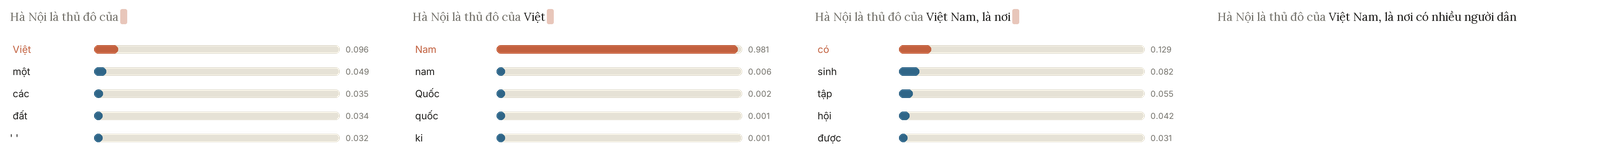

Beam search độ rộng $k$ giữ $k$ tiền tố có tổng log-xác suất cao nhất thay vì một. Mỗi bước, mỗi tiền tố được nối với mọi token, tạo $k|V|$ ứng viên, rồi chỉ $k$ ứng viên tốt nhất được giữ; tiền tố vừa gặp EOS được cất riêng thành câu hoàn chỉnh. Với $k=2$, ví dụ trên giữ cả A lẫn B ở bước đầu nên tìm ra `B EOS`; với $k=1$, beam search chính là greedy. Beam hữu hạn vẫn chỉ tìm gần đúng: tiền tố bị loại ở một bước không bao giờ quay lại. Mỗi token nối thêm cộng một số hạng $\log p\le0$, nên tổng log không bao giờ tăng và beam thuần ưu ái câu ngắn; length penalty chia điểm theo độ dài và vì vậy đổi mục tiêu xếp hạng. Chuỗi xác suất cao nhất cũng không nhất thiết tốt nhất theo metric của nhiệm vụ.

**Hỏi nhanh.** Giữ $p(A) = 0.6$, $p(B) = 0.4$ và $p(\mathrm{EOS}\mid A) = 0.5$ như hình, nhưng đổi $p(\mathrm{EOS}\mid B)$ thành $x$. Chỉ xét hai chuỗi `A EOS` và `B EOS`. Khi nào chuỗi greedy trả về không kém chuỗi còn lại?

- A. Với mọi $x$, vì A thắng ở bước đầu
- B. Khi $x \le 0.5$, tức không vượt $p(\mathrm{EOS}\mid A)$
- C. Khi $x \le 0.75$
- D. Khi $x < 0.6$, tức nhỏ hơn $p(A)$

<details><summary>Đáp án</summary>

C. Khi $x \le 0.75$

Greedy luôn chọn A rồi EOS, được $0.6\cdot 0.5 = 0.30$. Chuỗi `B EOS` có xác suất $0.4x$, không vượt 0.30 khi $x \le 0.75$. Với $0.5 < x \le 0.75$, bước thứ hai của B dễ hơn của A, nhưng chưa đủ bù cho việc thua ở bước đầu. So $x$ với 0.5 hay với 0.6 là so từng bước, đúng lối nghĩ cục bộ khiến greedy sai. Phải nhân cả chuỗi. Beam độ rộng 2 giữ cả hai nhánh, nên trả về chuỗi tốt hơn với mọi $x$.

</details>



## Perplexity và văn bản bị máy sửa

Ta có thể dùng loss language model làm một đặc trưng để phát hiện văn bản được chỉnh sửa: văn phong máy có thể khác corpus tham chiếu. Nhưng đây là bài phân loại có gold provenance và phân phối riêng, không có luật “PPL thấp là do AI”. Một học sinh viết câu thông dụng có thể có loss thấp; một model sinh thuật ngữ hiếm có thể có loss cao. Dịch, sửa chính tả, tác giả và chủ đề còn là các yếu tố gây nhiễu.

Muốn thử, ta cần cặp bản gốc/bản sửa với cách tạo được ghi lại, chia theo nguồn văn bản để hai bản của cùng một đoạn không sang hai tập. Chọn ngưỡng bằng validation; báo false positives và false negatives trên nhóm tác giả, chủ đề và cách sửa chưa thấy. Không dùng một score để kết luận gian lận của một người.

**Hỏi nhanh.** Một detector gắn nhãn “máy viết” khi PPL dưới một ngưỡng. Ngưỡng được chọn trên validation gồm bài văn của học sinh chuyên Văn và văn bản do model sinh. Đem detector chấm bài tiếng Anh của học sinh mới học, câu ngắn, từ thông dụng. Rủi ro lớn nhất là gì?

- A. False negative tăng, vì câu ngắn có PPL cao
- B. False positive tăng, vì câu đơn giản có PPL thấp
- C. Không có gì thay đổi, vì ngưỡng đã được chọn trên validation
- D. Không có gì thay đổi, vì PPL không phụ thuộc người viết

<details><summary>Đáp án</summary>

B. False positive tăng, vì câu đơn giản có PPL thấp

Từ thông dụng và cấu trúc lặp lại là những thứ model tham chiếu đoán dễ nhất. Bài của người mới học vì vậy có PPL thấp, và bị gắn nhãn máy viết dù do người viết. Ngưỡng chọn trên validation chỉ đáng tin trên phân phối giống validation, mà nhóm người viết mới là một phân phối khác. Độ ngắn của câu không phải yếu tố chính, vì PPL đã chia theo số token. Điều quyết định là các token dễ đoán đến đâu. Vì vậy phải báo lỗi theo từng nhóm tác giả, và không dùng một điểm số để kết luận về một người.

</details>

## Khi đi thi

- **In một cặp input/label trước khi train.** Giải mã vài token của `ids[:, :-1]` và `ids[:, 1:]` để thấy label dịch đúng một vị trí và vị trí đệm mang `-100`.
- **Kiểm causal mask bằng một phép thử.** Đổi token cuối của input thì logits ở mọi vị trí trước phải giữ nguyên. Validation PPL gần 1 chỉ sau vài trăm bước là dấu hiệu tương lai bị lộ, không phải model giỏi.
- **So PPL đúng giao thức.** Cùng tokenizer, vocabulary, cách xử lý BOS/EOS/UNK; gộp theo tổng số token hợp lệ; ghi loss validation tách khỏi train.
- **Chốt cấu hình sinh trước khi chấm.** Ghi `do_sample`, temperature, top-k/top-p, seed, `max_new_tokens` và điều kiện dừng; so các cấu hình trên cùng tập dev. Greedy hoặc beam cho output ổn định; sampling hợp khi cần nhiều mẫu để chọn lại.
- **Dự toán thời gian sinh.** Sinh tuần tự theo token: số prompt nhân `max_new_tokens` chia tốc độ đo được trên đúng máy cho mức xấu nhất; input cộng output phải nằm trong context window.

## Tóm tắt

- Language model dự đoán token tiếp theo; xác suất chuỗi là tích các xác suất có điều kiện, và EOS biến một tiền tố thành câu hoàn chỉnh.
- N-gram đếm trên cửa sổ cố định nên số đếm thưa; add-α tránh xác suất 0 nhưng quá mạnh khi vocabulary lớn.
- Train dùng label dịch một vị trí và causal mask; loss là NLL trung bình trên token hợp lệ, perplexity là exp của nó và chỉ so được khi cùng giao thức.
- Temperature, top-k, top-p đổi phân phối lấy mẫu; greedy và beam search tìm chuỗi xác suất cao nhưng chỉ gần đúng.
- Xác suất cao không bảo đảm đúng; điểm language model không xác định chắc chắn ai viết một văn bản.

## Kiểm tra cuối bài

**Câu 1.** Khi train, một causal LM tính dự đoán token kế tiếp cho cả 512 vị trí của một chuỗi chỉ trong một lần forward. Dùng chính model này để sinh tiếp 512 token mới thì cần gì?

- A. 512 bước nối tiếp nhau, vì bước sau cần token vừa sinh
- B. 512 bước chạy song song, vì mỗi vị trí có mask riêng
- C. Một lần forward, vì causal mask cho tính mọi vị trí cùng lúc
- D. Một lần forward, nếu lưu lại phần đã tính cho tiền tố

<details><summary>Đáp án</summary>

A. 512 bước nối tiếp nhau, vì bước sau cần token vừa sinh

Khi train, mọi token của chuỗi đã có sẵn, nên causal mask cho tính 512 dự đoán cùng lúc mà không vị trí nào đọc tương lai. Khi sinh, token thứ $t + 1$ là input của bước kế tiếp, nhưng nó chưa tồn tại cho tới khi bước $t$ chọn xong. Vì vậy các bước phải nối tiếp nhau, và đó chính là nghĩa của sinh tự hồi quy. Lưu lại phần đã tính cho tiền tố, như KV cache ở bài 6.6, giúp mỗi bước khỏi tính lại, nhưng không bỏ được tính tuần tự. Hai phương án “một lần forward” nhầm việc train với việc sinh. “Chạy song song” bỏ qua việc mỗi vị trí cần token đứng trước nó.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 239](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=86)

</details>

**Câu 2.** Dưới đây là ba cách tạo mask cho chuỗi dài `L`, dùng với `F.scaled_dot_product_attention`, nơi True nghĩa là được đọc.
```py
a = ~torch.triu(torch.ones(L, L), diagonal=1).bool()
b = torch.tril(torch.ones(L, L)).bool()
c = torch.ones(L, L).bool()
for i in range(L):
    c[i, i+1:] = False
```
Cách nào cho đúng causal mask, tức vị trí $i$ đọc được các vị trí $0, \ldots, i$?

- A. Chỉ `c`, vì chỉ vòng lặp mới giữ đúng đường chéo
- B. Chỉ `a` và `b`, vì vòng lặp ở `c` bỏ mất đường chéo
- C. Chỉ `b` và `c`, vì `a` bị đảo nên cấm cả quá khứ
- D. Cả ba, vì đều là tam giác dưới gồm cả đường chéo

<details><summary>Đáp án</summary>

D. Cả ba, vì đều là tam giác dưới gồm cả đường chéo

`triu(…, diagonal=1)` là True ở các ô $j > i$, tức tương lai. Đảo bằng `~` thì True ở $j \le i$, đúng như `tril`. Vòng lặp đặt False từ cột $i + 1$ trở đi, nên vẫn giữ đường chéo. `torch.equal` xác nhận ba tensor bằng nhau. Chỗ dễ nhầm là quy ước. Mask này đúng khi True nghĩa là được đọc. `nn.MultiheadAttention` dùng quy ước ngược lại (bài 3.9), nên ở đó phải truyền phần bù, tức chính `triu(…, diagonal=1)`.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 18](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=28)

</details>

**Câu 3.** Một đội train một causal LM nhỏ. Sau 300 bước, validation perplexity đã là 1.03, nhưng sinh greedy thì ra chuỗi vô nghĩa. Label đã được dịch đúng một vị trí. Nên kiểm gì trước?

- A. Tăng temperature, vì greedy làm chuỗi lặp lại
- B. Train thêm, vì perplexity chưa về đúng 1
- C. Kiểm causal mask, vì PPL gần 1 gợi ý tương lai bị lộ
- D. Đổi tokenizer, vì perplexity phụ thuộc tokenizer

<details><summary>Đáp án</summary>

C. Kiểm causal mask, vì PPL gần 1 gợi ý tương lai bị lộ

PPL 1.03 nghĩa là trung bình hình học của xác suất token đúng khoảng 0.97, quá tốt với một model nhỏ sau 300 bước. Thiếu causal mask thì vị trí $i$ đọc được token $i + 1$, chính là label, nên chỉ cần chép lại. Khi sinh, token tương lai chưa tồn tại, và model hỏng. Validation tính bằng cùng một forward, nên lỗi không lộ ra ở loss. Temperature không sửa được model hỏng. Train thêm chỉ làm PPL sát 1 hơn mà không đổi nguyên nhân. Tokenizer làm đổi thang đo, nhưng không giải thích được một con số gần như hoàn hảo.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 231](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=83)

</details>

**Câu 4.** Một causal LM vừa khởi tạo, vocabulary có 32 000 token, và logits ở bước đầu gần như bằng nhau. Validation perplexity ở bước 0 khoảng bao nhiêu?

- A. Khoảng 1/32 000, tức xác suất của mỗi token
- B. Khoảng 32 000, bằng kích thước vocabulary
- C. Khoảng 10.4, tức $\ln 32\,000$
- D. Khoảng 4.5, tức $\log_{10} 32\,000$

<details><summary>Đáp án</summary>

B. Khoảng 32 000, bằng kích thước vocabulary

Logits bằng nhau cho phân phối đều, mỗi token có xác suất $1/32\,000$. Loss là $\ln 32\,000 \approx 10.37$, đúng mốc $\log C$ của bài 3.3, và PPL $= e^{\text{loss}} = 32\,000$. Model phân vân đều giữa mọi token. 10.4 là loss, chưa lấy mũ. 4.5 là dùng nhầm log cơ số 10. $1/32\,000$ là xác suất, tức nghịch đảo của PPL. Đây là một mốc để kiểm cài đặt: PPL ban đầu lệch xa kích thước vocabulary thường do label, mask hoặc vocabulary bị sai.

</details>

**Câu 5.** Một đội sinh 5 lời giải cho mỗi đề, chạy test và giữ lời giải qua được nhiều test nhất. Với `do_sample=True, temperature=0.2`, cả 5 lời giải gần như giống hệt nhau. Nên chỉnh gì?

- A. Giữ temperature 0.2, chỉ đổi seed giữa 5 lần sinh
- B. Tăng temperature, và chọn mức cụ thể trên tập dev
- C. Chuyển sang greedy để 5 lần sinh ổn định hơn
- D. Tăng `max_new_tokens` để các lời giải dài khác nhau

<details><summary>Đáp án</summary>

B. Tăng temperature, và chọn mức cụ thể trên tập dev

Temperature thấp làm phân phối rất nhọn. Ở hầu hết các bước, token đứng đầu gần như luôn được rút, nên đổi seed hiếm khi tạo ra khác biệt. Tăng temperature làm phân phối phẳng hơn và tăng độ đa dạng, đúng thứ mà cách chọn lại bằng test cần. Mức cụ thể phải chọn trên dev, vì temperature quá cao sẽ sinh lời giải lạc đề. Greedy là tất định, nên 5 lần cũng như một. `max_new_tokens` chỉ giới hạn độ dài, không đổi phân phối ở từng bước.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 240](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=86)

</details>

**Câu 6.** Cấu hình sinh là `do_sample=True, top_k=1, temperature=1.5`. Chạy với 5 seed khác nhau, cả 5 output trùng nhau đến từng token. Vì sao?

- A. Vì temperature 1.5 quá cao nên sampling bị tắt
- B. Vì seed không được truyền vào bộ sinh nên RNG không đổi
- C. Vì top-k 1 giữ một token ngẫu nhiên, cố định theo prompt
- D. Vì top-k 1 chỉ giữ argmax, nên lần nào cũng là greedy

<details><summary>Đáp án</summary>

D. Vì top-k 1 chỉ giữ argmax, nên lần nào cũng là greedy

Top-k giữ $k$ token có xác suất cao nhất rồi rút trong số đó. Với $k = 1$ thì chỉ còn argmax, và temperature dương không đổi argmax, nên kết quả là greedy bất kể seed. Seed không được truyền cũng có thể làm output trùng, nhưng ở đây đã có một nguyên nhân chắc chắn, không cần giả định thêm lỗi. Temperature cao làm phân phối phẳng hơn chứ không tắt sampling. Top-k chọn theo xác suất, không chọn ngẫu nhiên. Ở đầu kia, top-k bằng cả vocabulary chính là sampling thường.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 241](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=87)

</details>

**Câu 7.** Mọi câu có đúng hai token. Ở bước đầu, $p(A) = 0.4$, $p(B) = 0.35$, $p(C) = 0.25$. Token thứ hai tốt nhất sau mỗi nhánh có xác suất có điều kiện 0.6 sau A, 0.5 sau B và 1.0 sau C. Beam search độ rộng 2 trả về câu có xác suất bao nhiêu?

- A. 0.24, vì câu tốt nhất đã bị loại ngay ở bước đầu
- B. 0.24, và đó chắc chắn là câu tối ưu toàn cục
- C. 0.25, vì beam search xét đủ mọi nhánh
- D. 0.175, vì beam search bỏ nhánh mà greedy chọn

<details><summary>Đáp án</summary>

A. 0.24, vì câu tốt nhất đã bị loại ngay ở bước đầu

Ở bước đầu, beam giữ A với 0.4 và B với 0.35, loại C với 0.25. Ở bước sau, câu tốt nhất từ A có $0.4\cdot 0.6 = 0.24$, từ B có $0.35\cdot 0.5 = 0.175$, nên beam trả về 0.24, trùng với greedy. Câu tốt nhất bắt đầu bằng C có $0.25\cdot 1.0 = 0.25$, nhưng tiền tố C đã bị cắt và không quay lại được. Beam hữu hạn chỉ tìm gần đúng, và phải beam độ rộng 3 mới tìm ra câu ấy. Beam không bỏ nhánh greedy, vì nhánh có xác suất cao nhất ở bước đầu luôn nằm trong $k$ nhánh được giữ.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 18](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=3)

</details>

**Câu 8.** Hai đội báo PPL trên cùng tập validation, cùng cách tách từ. Đội X thay mọi từ xuất hiện dưới 5 lần trong train bằng UNK, còn vocabulary 2000, và được PPL 45. Đội Y giữ vocabulary 20 000, được PPL 80. Ta kết luận được gì?

- A. X tốt hơn, vì PPL thấp hơn trên cùng một tập
- B. Y tốt hơn, vì vocabulary lớn mô tả câu đầy đủ hơn
- C. Chưa so được, vì đoán UNK dễ hơn đoán đúng từ hiếm
- D. Chưa so được, vì phải chia PPL cho kích thước vocabulary

<details><summary>Đáp án</summary>

C. Chưa so được, vì đoán UNK dễ hơn đoán đúng từ hiếm

Ở X, mọi từ hiếm gộp thành một token UNK xuất hiện thường xuyên. Đoán “sắp có một từ hiếm” dễ hơn nhiều so với đoán đúng đó là từ hiếm nào, việc mà Y phải làm. Hai PPL đo hai bài dự đoán khác nhau, dù trên cùng một tập văn bản. Muốn so thì phải dùng cùng vocabulary và cùng quy tắc UNK, hoặc một đơn vị chung như log-xác suất trên mỗi ký tự với các model không dùng UNK. Chia cho kích thước vocabulary không phải là một phép chuẩn hóa có nghĩa. Vocabulary lớn cũng không tự làm model tốt hơn.

</details>

**Câu 9.** Một detector văn bản bị máy sửa bắt được 90% số bài bị sửa, và gắn nhầm 5% số bài do người viết. Hai tỉ lệ này đo trên dữ liệu cùng phân phối với nơi dùng. Trong một khối lớp, khoảng 2% số bài thật sự bị máy sửa. Trong những bài bị gắn nhãn “máy sửa”, khoảng bao nhiêu phần trăm thật sự bị sửa?

- A. Khoảng 2%, bằng tỉ lệ bài bị sửa trong khối
- B. Khoảng 90%, bằng tỉ lệ bắt được bài bị sửa
- C. Khoảng 95%, vì chỉ 5% bài người viết bị gắn nhầm
- D. Khoảng 27%

<details><summary>Đáp án</summary>

D. Khoảng 27%

Xét 1000 bài. 20 bài bị sửa, detector bắt được 18. 980 bài do người viết, bị gắn nhầm $0.05\cdot 980 = 49$ bài. Có 67 bài bị gắn nhãn, nhưng chỉ 18 bài thật sự bị sửa, nên precision là $18/67 \approx 0.27$. Tỉ lệ gắn nhầm 5% nghe thì nhỏ, nhưng nhóm người viết đông gấp 49 lần nhóm bị sửa, nên báo nhầm áp đảo. 90% là recall, tính trên những bài bị sửa chứ không trên những bài bị gắn nhãn. 95% là tỉ lệ bài người viết không bị gắn nhầm. 2% là tỉ lệ nền trước khi có detector. Vì vậy phải báo precision ở đúng tỉ lệ nền của nơi dùng, và một nhãn “máy sửa” đơn lẻ không đủ để kết luận về một học sinh.

</details>

**Câu 10.** Một bản top-p viết `keep = np.cumsum(sorted_probability) < threshold`, thiếu phần trừ xác suất của chính token như trong bài. Với phân phối (0.9, 0.06, 0.04) và top-p 0.8, hàm trả về gì?

- A. Toàn `nan`, vì không token nào được giữ
- B. (1, 0, 0), giống bản đúng
- C. (0.9, 0.06, 0.04), không lọc gì
- D. Báo `ValueError`, vì ngưỡng không hợp lệ

<details><summary>Đáp án</summary>

A. Toàn `nan`, vì không token nào được giữ

Tổng dồn là 0.9, 0.96, 1.0, không giá trị nào dưới 0.8. Vì vậy `keep` toàn False, `result` toàn 0, và phép chia 0/0 cho `nan`. NumPy chỉ cảnh báo. `rng.choice` sau đó mới báo lỗi, vì xác suất chứa `nan`. Bản đúng so tổng của các token đứng trước, nên token đầu luôn được giữ, và kết quả là (1, 0, 0). Lỗi chỉ lộ ra khi token đầu đã vượt ngưỡng, tức đúng lúc model tự tin nhất. Với phân phối phẳng hơn, hàm sai chỉ bỏ sót token làm tổng vượt ngưỡng. Ngưỡng 0.8 hợp lệ, nên không có `ValueError`. Một unit test với phân phối rất nhọn sẽ bắt được lỗi này.

</details>

## Đọc thêm

- Jurafsky, Martin — [N-gram Language Models](https://web.stanford.edu/~jurafsky/slp3/3.pdf). Đọc smoothing, evaluation và perplexity.
- Jurafsky, Martin — [Transformers and Pretraining](https://web.stanford.edu/~jurafsky/slp3/7.pdf). Nối next-token training với causal attention và decoding.
- Dive into Deep Learning — [Language models](https://d2l.ai/chapter_recurrent-neural-networks/language-model.html). Đọc cách tạo input/target dịch vị trí.
- Holtzman et al. — [The Curious Case of Neural Text Degeneration](https://arxiv.org/abs/1904.09751). Bài đề xuất top-p (nucleus sampling); đọc phần so greedy, beam và sampling về độ lặp và độ đa dạng.
- Hugging Face — [Generation](https://huggingface.co/docs/transformers/main_classes/text_generation). Kiểm ý nghĩa `do_sample`, `temperature`, `top_k`, `top_p` và giới hạn sinh của API.